Rows: 7205
Columns: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7205 entries, 0 to 7204
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  7202 non-null   object 
 1   Country Code  7200 non-null   object 
 2   Series Name   7200 non-null   object 
 3   Series Code   7200 non-null   object 
 4   Time          7200 non-null   float64
 5   Time Code     7200 non-null   object 
 6   Value         4074 non-null   float64
dtypes: float64(2), object(5)
memory usage: 394.2+ KB
None
2.412565231323242 MB
Value           3131
Series Name        5
Country Code       5
Time               5
Series Code        5
Time Code          5
Country Name       3
dtype: int64


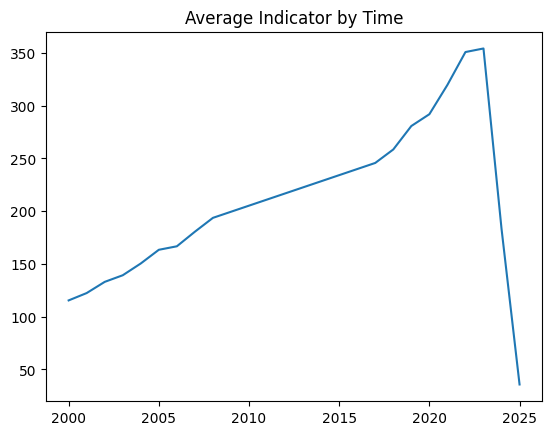

In [ ]:
# MODUL 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset (adjust path)
df = pd.read_csv('/content/drive/MyDrive/BIG-DATA/Tugas-1/Dataset/WDI.csv')
print('Rows:', len(df))
print('Columns:', df.shape[1])
print(df.info())

# Memory and missing values
print(df.memory_usage(deep=True).sum() / (1024**2), 'MB')
print(df.isnull().sum().sort_values(ascending=False).head(10))

# Simple aggregation example: average indicatosr by year
if 'Time' in df.columns and 'Value' in df.columns:
    yearly = df.groupby('Time')['Value'].mean().reset_index()
    plt.plot(yearly['Time'], yearly['Value'])
    plt.title('Average Indicator by Time')
    plt.show()

# Save cleaned sample
df_sample = df.sample(frac=0.01, random_state=42)  # 1% sample
df_sample.to_csv('/content/drive/MyDrive/BIG-DATA/Tugas-1/Output/WDI_sample.csv', index=False)

=== DATASET INFORMATION ===
Jumlah baris : 9998
Jumlah kolom : 20
Missing values : 0
Duplicate rows : 0


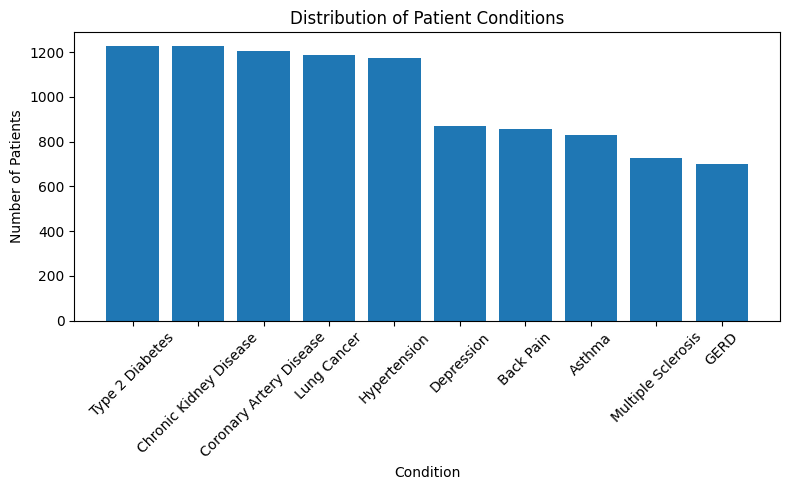

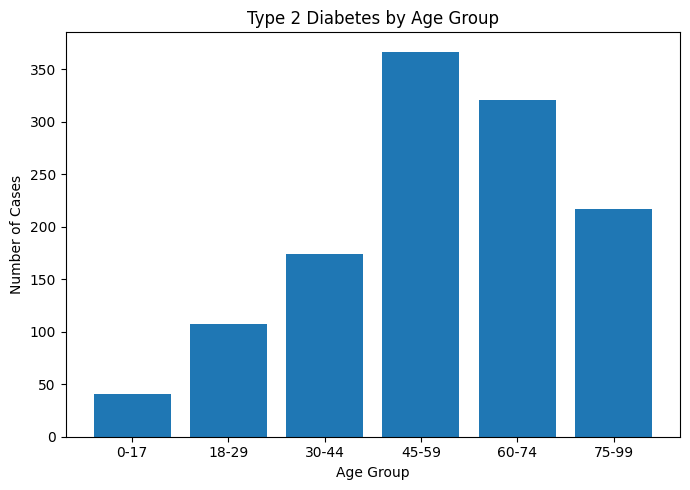

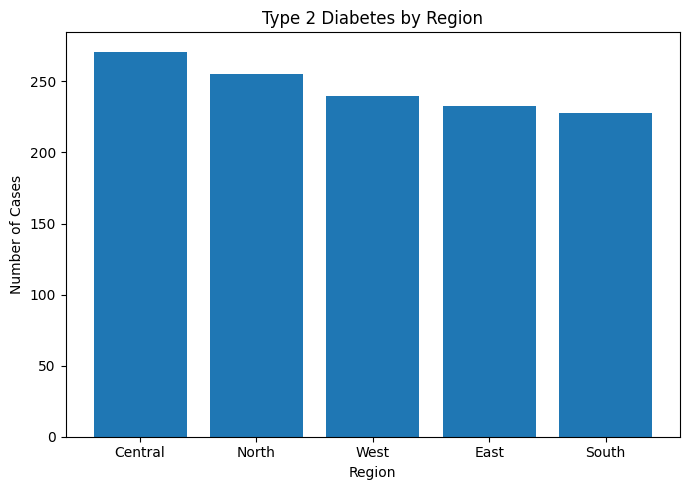


=== SUMMARY ===
Jumlah pasien diabetes : 1227
Region diabetes terbanyak : Central
Kelompok usia diabetes terbanyak : 45-59


In [ ]:
# CASE STUDY MODUL 1

import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/BIG-DATA/Tugas-1/Dataset/full_dataset_ehr.csv')

# =========================
# 1. PREPROCESSING
# =========================

# Hapus baris yang memiliki data kosong
df = df.dropna()
# Hapus data duplikat
df = df.drop_duplicates()


# =========================
# 2. Dataset Information
# =========================

print("=== DATASET INFORMATION ===")
print("Jumlah baris :", len(df))
print("Jumlah kolom :", df.shape[1])
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())


# =========================
# 3. Distribusi Kondisi
# =========================

condition = df['condition'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(condition.index, condition.values)

plt.title('Distribution of Patient Conditions')
plt.xlabel('Condition')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# =========================
# 4. Diabetes berdasarkan Umur
# =========================

# Filter pasien diabetes
diabetes = df[
    df['condition'].astype(str).str.lower().str.contains('diabetes')
]

age = diabetes['age_range'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(age.index, age.values)

plt.title('Type 2 Diabetes by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Cases')

plt.tight_layout()
plt.show()


# =========================
# 5. Region Diabetes
# =========================

diabetes_region = diabetes['region'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(diabetes_region.index, diabetes_region.values)

plt.title('Type 2 Diabetes by Region')
plt.xlabel('Region')
plt.ylabel('Number of Cases')

plt.tight_layout()
plt.show()


# =========================
# 6. Ringkasan
# =========================

print("\n=== SUMMARY ===")
print("Jumlah pasien diabetes :", len(diabetes))
print("Region diabetes terbanyak :", diabetes_region.idxmax())
print("Kelompok usia diabetes terbanyak :", age.idxmax())